# Efficient ResNet Challenge: CIFAR-10 under 5M parameters (A100, Drive-persistent, resumable)

**How to run:** Runtime > Change runtime type > A100 GPU, then Runtime > Run all.

**If the session dies:** reconnect and Run all again. The data loads from Drive (no re-download), the split loads from Drive (identical split), and training resumes from `last.pt` at the next epoch with optimizer, LR schedule and RNG state restored.

What is saved to Google Drive under `MyDrive/cifar10_resnet_challenge/`:

| Path | What |
|---|---|
| `data/raw_competition.tar` | the competition files exactly as downloaded (one file, Drive handles that better than 52k PNGs) |
| `data/cache/*.npy` + `manifest.json` | decoded images and labels, so later sessions load in seconds |
| `data/splits/*.npz` | the stratified train/val/test indices |
| `runs/<RUN_NAME>/last.pt` | full training state, written every epoch, used for resume |
| `runs/<RUN_NAME>/best.pt` | weights with the best validation accuracy |
| `runs/<RUN_NAME>/history.csv`, `config.json`, `submission_*.csv` | logs, config, submissions |

The data loaders do not assume column names. They detect which column holds file names/ids and which holds labels, require a 100% match with the image files, and stop with a printout if anything is ambiguous.

## 1. Config (every knob lives here)

In [1]:
CFG = dict(
    RUN_NAME="resnext29_4x24d_ta_ema_cutmix_sam_v1",
    KAGGLE_COMPETITION="cifar-10-res-net-architecture-challenge-dl",
    DRIVE_PROJECT_DIR="cifar10_resnet_challenge",
    LOCAL_DATA_DIR=None,

    SPLIT_SEED=42,
    VAL_FRAC=0.05,
    TEST_FRAC=0.05,

    ARCH="resnext",
    CARDINALITY=4,             # 4 groups
    BOTTLENECK_WIDTH=24,       # 24 channels per group (doubles each stage)
    WIDTHS=(256, 512, 1024),   # ResNeXt-29 stage output widths
    BLOCKS=(3, 3, 3),          # 3 stages x 3 blocks = 29 layers
    DROPOUT=0.0,
    PARAM_LIMIT=5_000_000,

    SEED=2,                    # different seed from the other models, for diversity
    EPOCHS=400,
    BATCH_SIZE=256,
    MAX_LR=0.2,
    MOMENTUM=0.9,
    WEIGHT_DECAY=5e-4,
    LABEL_SMOOTHING=0.1,
    PCT_WARMUP=0.25,
    EARLY_STOP_PATIENCE=None,
    MAX_EPOCHS_THIS_SESSION=None,

    AUGMENT=True,
    CUTOUT=8,
    TTA_FLIP=True,
    TRIVIAL_AUG=True,
    TA_GROUP=16,
    GRAYSCALE_P=0.1,

    EMA_DECAY=0.999,
    CUTMIX_P=0.5,
    CUTMIX_ALPHA=1.0,
    SAM_RHO=0.05,

    KD_ALPHA=0.0,              # trained on its own, no teachers
    KD_T=4.0,
    KD_MIN_TEACHER_VAL=0.965,
    TEACHER_RUNS=None,

    USE_BF16=True,
)
CFG

{'RUN_NAME': 'resnext29_4x24d_ta_ema_cutmix_sam_v1',
 'KAGGLE_COMPETITION': 'cifar-10-res-net-architecture-challenge-dl',
 'DRIVE_PROJECT_DIR': 'cifar10_resnet_challenge',
 'LOCAL_DATA_DIR': None,
 'SPLIT_SEED': 42,
 'VAL_FRAC': 0.05,
 'TEST_FRAC': 0.05,
 'ARCH': 'resnext',
 'CARDINALITY': 4,
 'BOTTLENECK_WIDTH': 24,
 'WIDTHS': (256, 512, 1024),
 'BLOCKS': (3, 3, 3),
 'DROPOUT': 0.0,
 'PARAM_LIMIT': 5000000,
 'SEED': 2,
 'EPOCHS': 400,
 'BATCH_SIZE': 256,
 'MAX_LR': 0.2,
 'MOMENTUM': 0.9,
 'WEIGHT_DECAY': 0.0005,
 'LABEL_SMOOTHING': 0.1,
 'PCT_WARMUP': 0.25,
 'EARLY_STOP_PATIENCE': None,
 'MAX_EPOCHS_THIS_SESSION': None,
 'AUGMENT': True,
 'CUTOUT': 8,
 'TTA_FLIP': True,
 'TRIVIAL_AUG': True,
 'TA_GROUP': 16,
 'GRAYSCALE_P': 0.1,
 'EMA_DECAY': 0.999,
 'CUTMIX_P': 0.5,
 'CUTMIX_ALPHA': 1.0,
 'SAM_RHO': 0.05,
 'KD_ALPHA': 0.0,
 'KD_T': 4.0,
 'KD_MIN_TEACHER_VAL': 0.965,
 'TEACHER_RUNS': None,
 'USE_BF16': True}

## 2. Environment, Drive, GPU

In [2]:
import os, sys, json, time, math, random, re, shutil, tarfile, zipfile, glob
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt

try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = os.path.join("/content/drive/MyDrive", CFG["DRIVE_PROJECT_DIR"])
    WORK_DIR = "/content/work"
else:
    DRIVE_ROOT = os.path.abspath(os.path.join(os.environ.get("DRIVE_ROOT_OVERRIDE", "./drive_sim"), CFG["DRIVE_PROJECT_DIR"]))
    WORK_DIR = os.path.abspath(os.environ.get("WORK_DIR_OVERRIDE", "./work"))

DATA_DIR  = os.path.join(DRIVE_ROOT, "data")
CACHE_DIR = os.path.join(DATA_DIR, "cache")
SPLIT_DIR = os.path.join(DATA_DIR, "splits")
RUN_DIR   = os.path.join(DRIVE_ROOT, "runs", CFG["RUN_NAME"])
for d in (CACHE_DIR, SPLIT_DIR, RUN_DIR, WORK_DIR):
    os.makedirs(d, exist_ok=True)
print("Drive project dir:", DRIVE_ROOT)
print("Run dir:", RUN_DIR)

if torch.cuda.is_available():
    device = torch.device("cuda")
    gpu = torch.cuda.get_device_name(0)
    print("GPU:", gpu)
    if "A100" not in gpu:
        print("WARNING: not an A100. Code still runs; bf16 needs Ampere or newer.")
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
else:
    device = torch.device("cpu")
    print("WARNING: no GPU found. In Colab: Runtime > Change runtime type > A100 GPU.")
print("torch", torch.__version__)

AMP_DTYPE = torch.bfloat16 if CFG["USE_BF16"] and (device.type == "cpu" or torch.cuda.is_bf16_supported()) else None

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(CFG["SEED"])

def atomic_torch_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

Mounted at /content/drive
Drive project dir: /content/drive/MyDrive/cifar10_resnet_challenge
Run dir: /content/drive/MyDrive/cifar10_resnet_challenge/runs/resnext29_4x24d_ta_ema_cutmix_sam_v1
GPU: NVIDIA A100-SXM4-80GB
torch 2.11.0+cu130


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
ZIP_PATH = os.path.join(DATA_DIR, "train_images.zip")
TRAIN_EXTRACT_DIR = os.path.join(WORK_DIR, "train_images")

print(f"Extracting train data from {ZIP_PATH} to {TRAIN_EXTRACT_DIR}...")
start_time = time.time()

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    # Extract all contents directly since the zip only contains train images
    zip_ref.extractall(path=TRAIN_EXTRACT_DIR)
    extracted_count = len(zip_ref.namelist())

print(f"Extracted {extracted_count} files in {time.time() - start_time:.2f} seconds.")

Extracting train data from /content/drive/MyDrive/cifar10_resnet_challenge/data/train_images.zip to /content/work/train_images...
Extracted 50000 files in 7.22 seconds.


## 3. Get the competition data (Drive first, Kaggle only if needed)

Order of preference: decoded cache on Drive, then the raw archive on Drive, then a fresh kagglehub download (which is then archived to Drive).

For the Kaggle download you need to have joined the competition and accepted its rules. Credentials: either add `KAGGLE_USERNAME` and `KAGGLE_KEY` in Colab's Secrets panel (key icon on the left, toggle notebook access on), or you will get an interactive login prompt.

In [5]:
# ---- Section 3: load competition data from Google Drive (no Kaggle) ----
MANIFEST = os.path.join(CACHE_DIR, "manifest.json")
RAW_DIR = os.path.join(WORK_DIR, "raw")      # local Colab disk (fast)

def extract_zip(zpath, dest_root):
    stem = os.path.splitext(os.path.basename(zpath))[0]
    t0 = time.time()
    with zipfile.ZipFile(zpath) as z:
        members = [m for m in z.namelist()
                   if not m.startswith("__MACOSX") and not os.path.basename(m).startswith("._") and not m.endswith(".DS_Store")]
        has_top = all(m.startswith(stem + "/") for m in members)
        dest = dest_root if has_top else os.path.join(dest_root, stem)
        for m in members:
            z.extract(m, dest)
    print(f"extracted {os.path.basename(zpath)} ({len(members)} entries) in {time.time()-t0:.0f}s")

def copy_folder(src, dst):
    os.makedirs(dst, exist_ok=True)
    files = [f for f in os.listdir(src) if not f.startswith(".")]
    t0 = time.time()
    for i, f in enumerate(files, 1):
        shutil.copy(os.path.join(src, f), os.path.join(dst, f))
        if i % 500 == 0 or i == len(files):
            print(f"  copied {i}/{len(files)} files ({time.time()-t0:.0f}s)")

def get_data_from_drive():
    os.makedirs(RAW_DIR, exist_ok=True)
    for name in ["train_images", "test_images"]:
        local = os.path.join(RAW_DIR, name)
        if os.path.isdir(local) and os.listdir(local):
            print(name, "already on local disk"); continue
        zp, fp = os.path.join(DATA_DIR, name + ".zip"), os.path.join(DATA_DIR, name)
        if os.path.exists(zp):
            extract_zip(zp, RAW_DIR)
        elif os.path.isdir(fp):
            print(f"copying {name} folder from Drive ...")
            copy_folder(fp, local)
        else:
            raise FileNotFoundError(f"Neither {zp} nor folder {fp} found")
    for f in ["train_labels.csv", "test.csv", "sample_submission.csv"]:
        src = os.path.join(DATA_DIR, f)
        assert os.path.exists(src), f"Missing {src}"
        shutil.copy(src, os.path.join(RAW_DIR, f))
    return RAW_DIR

NEED_BUILD = not os.path.exists(MANIFEST)
if NEED_BUILD:
    SRC_DIR = get_data_from_drive()
    print("\nCompetition files:")
    for root, dirs, files in os.walk(SRC_DIR):
        if root[len(SRC_DIR):].count(os.sep) <= 2:
            print(" ", root, "|", len(files), "files", sorted(files)[:3])
else:
    print("Decoded cache found on Drive, skipping raw files:", MANIFEST)

Decoded cache found on Drive, skipping raw files: /content/drive/MyDrive/cifar10_resnet_challenge/data/cache/manifest.json


## 4. Build the decoded cache (first session only)

Each CSV is matched to the image files by trying every column as an exact file name, file stem, or numeric id, and only a 100% one-to-one match is accepted. Labels may be integers 0 to 9 or class names. The test ids are aligned to `sample_submission.csv`. Every decision is printed so you can confirm it.

In [6]:
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp")

def find_path(root, name, want_dir):
    hits = []
    for r, ds, fs in os.walk(root):
        pool = ds if want_dir else fs
        if name in pool:
            hits.append(os.path.join(r, name))
    hits.sort(key=lambda p: p.count(os.sep))
    return hits[0] if hits else None

def list_images(d):
    out = [os.path.join(r, f) for r, _, fs in os.walk(d) for f in fs if f.lower().endswith(IMG_EXT)]
    return sorted(out)

def file_index(files):
    base = {os.path.basename(f): f for f in files}
    stem = {os.path.splitext(os.path.basename(f))[0]: f for f in files}
    num = {}
    for f in files:
        m = re.findall(r"\d+", os.path.splitext(os.path.basename(f))[0])
        if m: num.setdefault(int(m[-1]), []).append(f)
    num = {k: v[0] for k, v in num.items() if len(v) == 1} if all(len(v) == 1 for v in num.values()) and len(num) == len(files) else None
    assert len(base) == len(files), "Duplicate image file names in different subfolders."
    return {"basename": base, "stem": stem, "numeric": num}

def map_column(series, idx, strategy):
    if strategy == "numeric":
        if idx["numeric"] is None: return None
        v = pd.to_numeric(series, errors="coerce")
        if v.isna().any() or (v % 1 != 0).any(): return None
        return v.astype(int).map(idx["numeric"])
    s = series.astype(str).str.strip()
    if strategy == "basename": s = s.map(os.path.basename)
    return s.map(idx[strategy])

def resolve_key(df, files, name):
    idx = file_index(files)
    rows = []
    for strategy in ("basename", "stem", "numeric"):
        for col in df.columns:
            m = map_column(df[col], idx, strategy)
            frac = 0.0 if m is None else m.notna().mean()
            uniq = m is not None and m.notna().all() and m.nunique() == len(df)
            rows.append((col, strategy, round(float(frac), 4), uniq))
    print(f"[{name}] key candidates (column, strategy, match fraction, one-to-one):")
    for r in rows:
        if r[2] > 0: print("   ", r)
    ok = [r for r in rows if r[2] == 1.0 and r[3]]
    if not ok:
        raise RuntimeError(f"[{name}] no column maps 1:1 onto the {len(files)} image files. CSV head:\n{df.head()}\n"
                           f"file examples: {[os.path.basename(f) for f in files[:5]]}")
    col, strategy = ok[0][0], ok[0][1]
    print(f"[{name}] using column '{col}' as {strategy} key")
    return col, map_column(df[col], idx, strategy).values

def resolve_labels(df, key_col):
    cands = {}
    for col in df.columns:
        if col == key_col: continue
        s = df[col]
        v = pd.to_numeric(s, errors="coerce")
        if v.notna().all() and (v % 1 == 0).all() and set(v.astype(int).unique()) <= set(range(10)) and v.nunique() == 10:
            cands[col] = v.astype(int).values
        elif v.isna().all():   # text column (works for object and pandas string dtypes)
            low = s.astype(str).str.strip().str.lower()
            if set(low.unique()) <= set(CLASS_NAMES) and low.nunique() == 10:
                cands[col] = low.map({c: i for i, c in enumerate(CLASS_NAMES)}).values
    if not cands:
        raise RuntimeError(f"No label column found. Columns: {list(df.columns)}\n{df.head()}")
    cols = list(cands)
    for c in cols[1:]:
        assert (cands[c] == cands[cols[0]]).all(), f"Label columns {cols[0]} and {c} disagree."
    print(f"[train] label column(s): {cols} -> using '{cols[0]}'")
    return cands[cols[0]]

def decode(paths):
    def one(p):
        a = np.array(Image.open(p).convert("RGB"))
        assert a.shape == (32, 32, 3), f"{p} has shape {a.shape}"
        return a
    with ThreadPoolExecutor(16) as ex:
        return np.stack(list(ex.map(one, paths)))

if NEED_BUILD:
    tr_csv = find_path(SRC_DIR, "train_labels.csv", False)
    te_csv = find_path(SRC_DIR, "test.csv", False)
    ss_csv = find_path(SRC_DIR, "sample_submission.csv", False)
    tr_dir = find_path(SRC_DIR, "train_images", True)
    te_dir = find_path(SRC_DIR, "test_images", True)
    print("train csv:", tr_csv, "\ntest csv:", te_csv, "\nsample sub:", ss_csv, "\ntrain dir:", tr_dir, "\ntest dir:", te_dir)
    assert tr_csv and ss_csv and tr_dir and te_dir, "Expected files not found, see listing above."

    # ---------- train ----------
    tr_df = pd.read_csv(tr_csv)
    print("\ntrain_labels.csv", tr_df.shape, "\n", tr_df.head())
    tr_files = list_images(tr_dir)
    print("train images:", len(tr_files))
    assert len(tr_df) == len(tr_files), f"{len(tr_df)} label rows vs {len(tr_files)} images"
    key_col, tr_paths = resolve_key(tr_df, tr_files, "train")
    y_full = resolve_labels(tr_df, key_col).astype(np.int64)

    # ---------- test ----------
    ss = pd.read_csv(ss_csv)
    print("\nsample_submission", ss.shape, "\n", ss.head(3))
    assert list(ss.columns) == ["id", "label"], ss.columns
    te_files = list_images(te_dir)
    print("test images:", len(te_files))
    assert len(te_files) == len(ss), f"{len(te_files)} test images vs {len(ss)} submission rows"
    sub_ids = set(ss["id"].tolist())
    te_df = pd.read_csv(te_csv) if te_csv else None
    id_cols = []
    if te_df is not None:
        print("\ntest.csv", te_df.shape, "\n", te_df.head())
        tkey, te_paths = resolve_key(te_df, te_files, "test")
        for c in te_df.columns:
            v = pd.to_numeric(te_df[c], errors="coerce")
            if v.notna().all() and (v % 1 == 0).all() and set(v.astype(int).tolist()) == sub_ids:
                id_cols.append(c)
    if id_cols:
        id_col = "id" if "id" in id_cols else id_cols[0]
        print(f"[test] id column in test.csv: '{id_col}'")
        te_ids = pd.to_numeric(te_df[id_col]).astype(int).values
    else:
        print("[test] test.csv missing or has no id column matching sample_submission, trying file numbers")
        idx = file_index(te_files)
        assert idx["numeric"] is not None and set(idx["numeric"]) == sub_ids, "No test.csv and file numbers do not match ids."
        te_ids = np.array(sorted(sub_ids)); te_paths = np.array([idx["numeric"][i] for i in te_ids])
        print("[test] ids taken from file numbers")
    order = pd.Series(range(len(te_ids)), index=te_ids).loc[ss["id"].values].values   # sample_submission order
    te_ids, te_paths = te_ids[order], np.asarray(te_paths)[order]
    print("[test] first mappings:", list(zip(te_ids[:5].tolist(), [os.path.basename(p) for p in te_paths[:5]])))

    print("\nDecoding images ...")
    t0 = time.time()
    X_full = decode(tr_paths); X_test = decode(te_paths)
    print(f"decoded in {time.time()-t0:.0f}s", X_full.shape, X_test.shape)

    np.save(os.path.join(CACHE_DIR, "train_x.npy"), X_full)
    np.save(os.path.join(CACHE_DIR, "train_y.npy"), y_full)
    np.save(os.path.join(CACHE_DIR, "train_files.npy"), np.array([os.path.basename(p) for p in tr_paths]))
    np.save(os.path.join(CACHE_DIR, "test_x.npy"), X_test)
    np.save(os.path.join(CACHE_DIR, "test_ids.npy"), te_ids)
    np.save(os.path.join(CACHE_DIR, "test_files.npy"), np.array([os.path.basename(p) for p in te_paths]))
    ss.to_csv(os.path.join(CACHE_DIR, "sample_submission.csv"), index=False)
    with open(MANIFEST, "w") as f:   # written last: its presence means the cache is complete
        json.dump({"n_train": int(len(X_full)), "n_test": int(len(X_test)), "train_key_col": key_col,
                   "created": time.strftime("%Y-%m-%d %H:%M:%S")}, f, indent=1)
    print("Cache saved to Drive:", CACHE_DIR)

## 5. Load cache and sanity-check it

manifest: {'n_train': 50000, 'n_test': 2000, 'train_key_col': 'filename', 'created': '2026-10-30 04:09:47'}
train: (50000, 32, 32, 3) uint8 | test: (2000, 32, 32, 3)
class counts: {'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


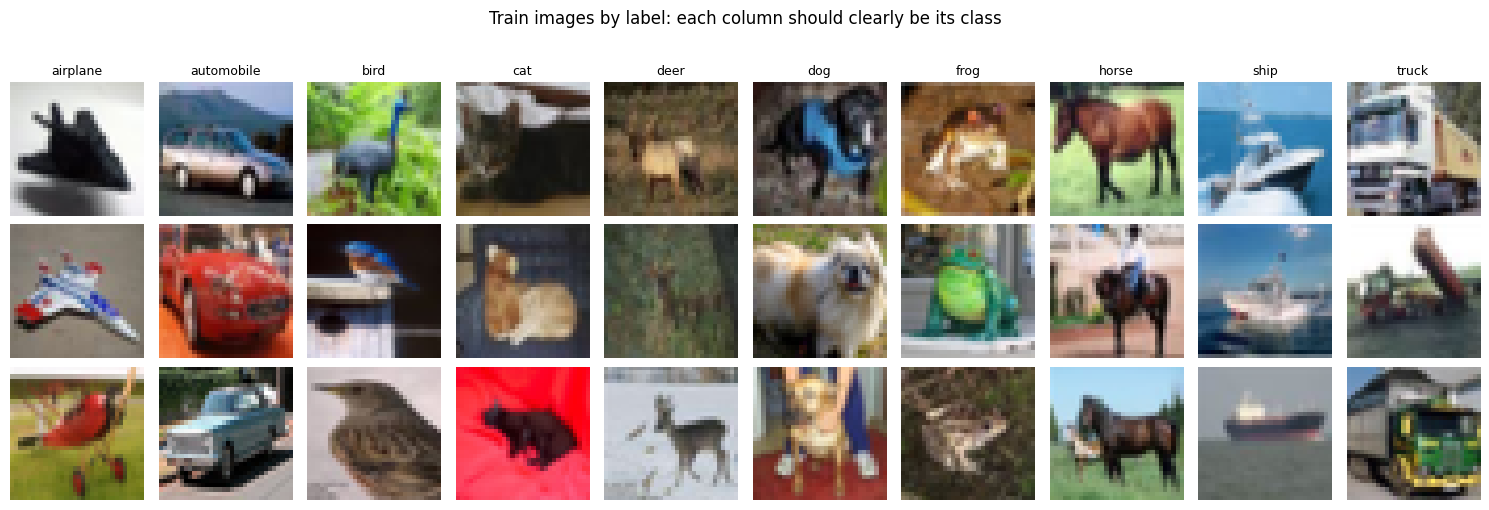

In [7]:
X_full = np.load(os.path.join(CACHE_DIR, "train_x.npy"))
y_full = np.load(os.path.join(CACHE_DIR, "train_y.npy"))
X_test = np.load(os.path.join(CACHE_DIR, "test_x.npy"))
test_ids = np.load(os.path.join(CACHE_DIR, "test_ids.npy"))
SAMPLE_SUB = pd.read_csv(os.path.join(CACHE_DIR, "sample_submission.csv"))
print("manifest:", json.load(open(MANIFEST)))
print("train:", X_full.shape, X_full.dtype, "| test:", X_test.shape)
assert X_full.dtype == np.uint8 and X_full.shape[1:] == (32, 32, 3)
assert len(X_full) == len(y_full) and (test_ids == SAMPLE_SUB["id"].values).all()
counts = np.bincount(y_full, minlength=10)
print("class counts:", dict(zip(CLASS_NAMES, counts.tolist())))

fig, axs = plt.subplots(3, 10, figsize=(15, 5))
for c in range(10):
    for r, i in enumerate(np.where(y_full == c)[0][:3]):
        axs[r, c].imshow(X_full[i]); axs[r, c].axis("off")
    axs[0, c].set_title(CLASS_NAMES[c], fontsize=9)
plt.suptitle("Train images by label: each column should clearly be its class", y=1.02); plt.tight_layout(); plt.show()

## 6. Stratified train / val / test split

`train_test_split(..., stratify=y)` twice, so all three parts have the same class proportions (250 per class in val and in test when the data is balanced). The internal test part is only scored once at the end, so it gives an honest estimate of leaderboard accuracy. The split is saved to Drive and reused by every run and every resume.

In [8]:
from sklearn.model_selection import train_test_split
split_path = os.path.join(SPLIT_DIR, f"split_seed{CFG['SPLIT_SEED']}_val{CFG['VAL_FRAC']}_test{CFG['TEST_FRAC']}_n{len(y_full)}.npz")
if os.path.exists(split_path):
    s = np.load(split_path); tr_idx, va_idx, te_idx = s["train"], s["val"], s["test"]
    print("Loaded split from Drive:", split_path)
else:
    all_idx = np.arange(len(y_full))
    trva_idx, te_idx = train_test_split(all_idx, test_size=CFG["TEST_FRAC"], stratify=y_full, random_state=CFG["SPLIT_SEED"])
    tr_idx, va_idx = train_test_split(trva_idx, test_size=CFG["VAL_FRAC"] / (1 - CFG["TEST_FRAC"]),
                                      stratify=y_full[trva_idx], random_state=CFG["SPLIT_SEED"])
    np.savez(split_path, train=tr_idx, val=va_idx, test=te_idx)
    print("Saved split to Drive:", split_path)
assert len(set(tr_idx) & set(va_idx)) == 0 and len(set(tr_idx) & set(te_idx)) == 0 and len(set(va_idx) & set(te_idx)) == 0
assert len(tr_idx) + len(va_idx) + len(te_idx) == len(y_full)
tab = pd.DataFrame({n: np.bincount(y_full[i], minlength=10) for n, i in [("train", tr_idx), ("val", va_idx), ("test", te_idx)]},
                   index=CLASS_NAMES)
tab.loc["TOTAL"] = tab.sum()
print(tab)

Loaded split from Drive: /content/drive/MyDrive/cifar10_resnet_challenge/data/splits/split_seed42_val0.05_test0.05_n50000.npz
            train   val  test
airplane     4500   250   250
automobile   4500   250   250
bird         4500   250   250
cat          4500   250   250
deer         4500   250   250
dog          4500   250   250
frog         4500   250   250
horse        4500   250   250
ship         4500   250   250
truck        4500   250   250
TOTAL       45000  2500  2500


## 7. GPU tensors, normalisation, optional augmentation

mean [0.4912, 0.4821, 0.4464] std [0.2469, 0.2434, 0.2616]
augmentation: ON | TrivialAugment: True | grayscale p: 0.1 | train (45000, 3, 32, 32) val (2500, 3, 32, 32) internal test (2500, 3, 32, 32) kaggle test (2000, 3, 32, 32)


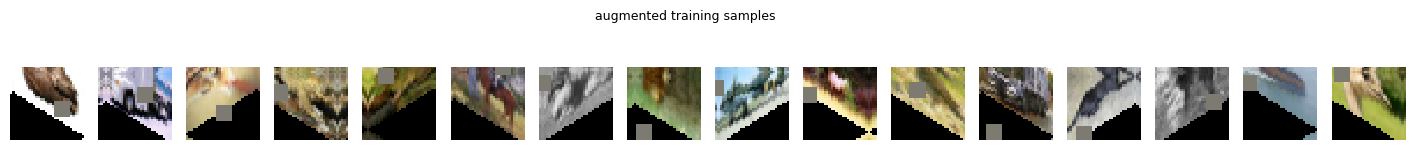

In [9]:
from torchvision.transforms import v2 as T

def to_dev(x): return torch.from_numpy(x).permute(0, 3, 1, 2).contiguous().to(device)   # N,3,32,32 uint8
Xtr, ytr = to_dev(X_full[tr_idx]), torch.from_numpy(y_full[tr_idx]).to(device)
Xva, yva = to_dev(X_full[va_idx]), torch.from_numpy(y_full[va_idx]).to(device)
Xte_int, yte_int = to_dev(X_full[te_idx]), torch.from_numpy(y_full[te_idx]).to(device)
Xkaggle = to_dev(X_test)

# statistics from the training part only (no leakage from val/test)
_f = Xtr.float() / 255
MEAN = _f.mean(dim=(0, 2, 3)).view(1, 3, 1, 1); STD = _f.std(dim=(0, 2, 3)).view(1, 3, 1, 1); del _f
print("mean", [round(v, 4) for v in MEAN.flatten().tolist()], "std", [round(v, 4) for v in STD.flatten().tolist()])

def normalize(x_u8):
    x = (x_u8.float() / 255 - MEAN) / STD
    return x.contiguous(memory_format=torch.channels_last)

_trivial = T.TrivialAugmentWide()

def photometric(x_u8):
    """TrivialAugment (one random op per small group of images) + random grayscale, on uint8 GPU tensors."""
    if CFG.get("TRIVIAL_AUG", False):
        g = CFG.get("TA_GROUP", 8)
        x_u8 = torch.cat([_trivial(c) for c in x_u8.split(g)])      # each chunk of g images gets its own random op
    p = CFG.get("GRAYSCALE_P", 0.0)
    if p > 0:
        gray = (x_u8.float() * torch.tensor([0.299, 0.587, 0.114], device=x_u8.device).view(1, 3, 1, 1)).sum(1, keepdim=True)
        gray = gray.round().clamp(0, 255).to(torch.uint8).expand(-1, 3, -1, -1)
        m = (torch.rand(len(x_u8), device=x_u8.device) < p)[:, None, None, None]
        x_u8 = torch.where(m, gray, x_u8)
    return x_u8

def augment(x_u8):
    x_u8 = photometric(x_u8)
    x = (x_u8.float() / 255 - MEAN) / STD
    n, dev = x.size(0), x.device
    xp = F.pad(x, (4, 4, 4, 4), mode="reflect")
    dy = torch.randint(0, 9, (n,), device=dev); dx = torch.randint(0, 9, (n,), device=dev)
    ar = torch.arange(32, device=dev)
    x = xp[torch.arange(n, device=dev)[:, None, None, None], torch.arange(3, device=dev)[None, :, None, None],
           (dy[:, None] + ar)[:, None, :, None], (dx[:, None] + ar)[:, None, None, :]]
    flip = torch.rand(n, device=dev) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    if CFG["CUTOUT"] > 0:
        cy = torch.randint(0, 32, (n,), device=dev); cx = torch.randint(0, 32, (n,), device=dev); h = CFG["CUTOUT"] // 2
        m = ((ar[None, :, None] - cy[:, None, None]).abs() < h) & ((ar[None, None, :] - cx[:, None, None]).abs() < h)
        x = x * (~m)[:, None].float()
    return x.contiguous(memory_format=torch.channels_last)

prep_train = augment if CFG["AUGMENT"] else normalize
print("augmentation:", "ON" if CFG["AUGMENT"] else "OFF",
      "| TrivialAugment:", CFG.get("TRIVIAL_AUG", False), "| grayscale p:", CFG.get("GRAYSCALE_P", 0.0),
      "| train", tuple(Xtr.shape), "val", tuple(Xva.shape), "internal test", tuple(Xte_int.shape), "kaggle test", tuple(Xkaggle.shape))

# preview: 16 training images after augmentation (un-normalised for display)
if CFG["AUGMENT"]:
    _s = augment(Xtr[:16]).float() * STD + MEAN
    fig, axs = plt.subplots(1, 16, figsize=(18, 1.6))
    for a, im in zip(axs, _s.clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()):
        a.imshow(im, interpolation="nearest"); a.axis("off")
    plt.suptitle("augmented training samples", y=1.08, fontsize=9); plt.show()

## 8. Model

CIFAR-style ResNet: 3x3 stem, three stages of BasicBlocks (64, 128, 256 channels, 3 blocks each), identity skips, 1x1 conv + BN projection skips where shape changes, global average pool, linear head. Downsampling happens only twice, so the last stage still works on 8x8 maps, which suits 32x32 inputs better than ImageNet ResNets. Zero-init of the last BN in each block makes every block start as an identity, which stabilises early training.

In [10]:
# ---- 8. Models: our ResNet + ResNeXt-29, chosen with CFG["ARCH"] ----
class BasicBlock(nn.Module):
    """Post-activation basic block (our original ResNet)."""
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = nn.Identity()
        if stride != 1 or cin != cout:
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x), inplace=True)

class CifarResNet(nn.Module):
    def __init__(self, widths=(64, 128, 256), blocks=(3, 3, 3), num_classes=10, dropout=0.0):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        layers, cin = [], widths[0]
        for i, (w, nb) in enumerate(zip(widths, blocks)):
            for j in range(nb):
                layers.append(BasicBlock(cin, w, 2 if (j == 0 and i > 0) else 1)); cin = w
        self.layers = nn.Sequential(*layers)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        for b in self.layers: nn.init.zeros_(b.bn2.weight)
    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(self.drop(torch.flatten(F.adaptive_avg_pool2d(x, 1), 1)))

class ResNeXtBlock(nn.Module):
    """ResNeXt bottleneck: 1x1 conv -> grouped 3x3 conv (cardinality groups) -> 1x1 conv, plus skip (Xie et al. 2017)."""
    def __init__(self, cin, inner, cout, stride, cardinality):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, inner, 1, bias=False); self.bn1 = nn.BatchNorm2d(inner)
        self.conv2 = nn.Conv2d(inner, inner, 3, stride, 1, groups=cardinality, bias=False); self.bn2 = nn.BatchNorm2d(inner)
        self.conv3 = nn.Conv2d(inner, cout, 1, bias=False); self.bn3 = nn.BatchNorm2d(cout)
        self.shortcut = nn.Identity()
        if stride != 1 or cin != cout:
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = F.relu(self.bn2(self.conv2(out)), inplace=True)
        out = self.bn3(self.conv3(out))
        return F.relu(out + self.shortcut(x), inplace=True)

class ResNeXt29(nn.Module):
    """CIFAR ResNeXt-29: 3x3 stem (64) + 3 stages x 3 blocks; output widths 256/512/1024;
    inner width = cardinality * bottleneck_width, doubled at each stage. (2, 64) is the standard 2x64d."""
    def __init__(self, cardinality=2, bottleneck_width=64, blocks=(3, 3, 3), out_widths=(256, 512, 1024),
                 num_classes=10, dropout=0.0, stem=64):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, stem, 3, 1, 1, bias=False), nn.BatchNorm2d(stem), nn.ReLU(inplace=True))
        layers, cin = [], stem
        for i, (cout, nb) in enumerate(zip(out_widths, blocks)):
            inner = cardinality * bottleneck_width * (2 ** i)
            for j in range(nb):
                layers.append(ResNeXtBlock(cin, inner, cout, 2 if (j == 0 and i > 0) else 1, cardinality)); cin = cout
        self.layers = nn.Sequential(*layers)
        self.drop = nn.Dropout(dropout); self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        for b in self.layers: nn.init.zeros_(b.bn3.weight)
    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(self.drop(torch.flatten(F.adaptive_avg_pool2d(x, 1), 1)))

def build_model(c):
    """Build any of our architectures from a config dict (also rebuilds teachers from their saved cfg)."""
    arch = c.get("ARCH", "resnet")
    if arch == "resnet":
        return CifarResNet(c["WIDTHS"], c["BLOCKS"], dropout=c.get("DROPOUT", 0.0))
    if arch == "resnext":
        return ResNeXt29(c.get("CARDINALITY", 2), c.get("BOTTLENECK_WIDTH", 64), c.get("BLOCKS", (3, 3, 3)),
                         c.get("WIDTHS", (256, 512, 1024)), dropout=c.get("DROPOUT", 0.0))
    raise ValueError(f"unknown ARCH {arch}")

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

model = build_model(CFG).to(device).to(memory_format=torch.channels_last)
N_PARAMS = count_params(model)
print(f"ARCH={CFG.get('ARCH', 'resnet')} | trainable parameters: {N_PARAMS:,}  (limit {CFG['PARAM_LIMIT']:,}, headroom {CFG['PARAM_LIMIT']-N_PARAMS:,})")
assert N_PARAMS <= CFG["PARAM_LIMIT"], "Model is over the parameter limit."

ARCH=resnext | trainable parameters: 4,845,002  (limit 5,000,000, headroom 154,998)


## 9. Optimiser, schedule, checkpoint helpers

In [11]:
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn

decay, no_decay = [], []
for n, p in model.named_parameters():
    (no_decay if p.ndim <= 1 else decay).append(p)       # no weight decay on BN and biases
optimizer = torch.optim.SGD([{"params": decay, "weight_decay": CFG["WEIGHT_DECAY"]},
                             {"params": no_decay, "weight_decay": 0.0}],
                            lr=CFG["MAX_LR"], momentum=CFG["MOMENTUM"], nesterov=True)
STEPS_PER_EPOCH = math.ceil(len(Xtr) / CFG["BATCH_SIZE"])
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=CFG["MAX_LR"], epochs=CFG["EPOCHS"],
                                                steps_per_epoch=STEPS_PER_EPOCH, pct_start=CFG["PCT_WARMUP"],
                                                anneal_strategy="cos", div_factor=25, final_div_factor=1e4)
criterion = nn.CrossEntropyLoss(label_smoothing=CFG["LABEL_SMOOTHING"])

# EMA: a running average of the weights (and BN statistics). Not trained, so it adds no trainable parameters.
ema = None
if CFG.get("EMA_DECAY"):
    ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(CFG["EMA_DECAY"]), use_buffers=True)
    for p in ema.parameters(): p.requires_grad_(False)
print("EMA:", f"decay {CFG['EMA_DECAY']}" if ema is not None else "off",
      "| CutMix:", f"p={CFG.get('CUTMIX_P', 0)}, alpha={CFG.get('CUTMIX_ALPHA', 1.0)}" if CFG.get("CUTMIX_P", 0) > 0 else "off")

def cutmix(x, y, alpha):
    """Paste a random box from a shuffled copy of the batch; labels are mixed by the pasted area."""
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    H, W = x.size(2), x.size(3); r = math.sqrt(1.0 - lam)
    ch, cw = int(H * r), int(W * r)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, H)
    x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, W)
    x = x.clone()
    x[:, :, y1:y2, x1:x2] = x[idx, :, y1:y2, x1:x2]
    lam = 1.0 - (y2 - y1) * (x2 - x1) / (H * W)
    return x, y, y[idx], lam

LAST_CKPT = os.path.join(RUN_DIR, "last.pt")
BEST_CKPT = os.path.join(RUN_DIR, "best.pt")
HIST_CSV  = os.path.join(RUN_DIR, "history.csv")
# settings that must not change between a run and its resume
LOCKED = ["WIDTHS", "BLOCKS", "DROPOUT", "EPOCHS", "BATCH_SIZE", "MAX_LR", "WEIGHT_DECAY", "MOMENTUM",
          "LABEL_SMOOTHING", "PCT_WARMUP", "AUGMENT", "CUTOUT", "SPLIT_SEED", "VAL_FRAC", "TEST_FRAC", "SEED",
          "TRIVIAL_AUG", "TA_GROUP", "GRAYSCALE_P", "EMA_DECAY", "CUTMIX_P", "CUTMIX_ALPHA"]

def rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}

def set_rng_state(s):
    random.setstate(s["python"]); np.random.set_state(s["numpy"])
    torch.set_rng_state(s["torch"].cpu())
    if s["cuda"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([t.cpu() for t in s["cuda"]])

def norm_stats(): return {"mean": MEAN.cpu(), "std": STD.cpu()}

@torch.no_grad()
def predict_logits(m, X, bs=1024, tta=False):
    m.eval(); out = []
    for i in range(0, len(X), bs):
        xb = normalize(X[i:i + bs])
        with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
            lo = m(xb).float().softmax(1)
            if tta: lo = lo + m(xb.flip(3)).float().softmax(1)
        out.append(lo)
    return torch.cat(out)

def evaluate(m, X, y, tta=False):
    p = predict_logits(m, X, tta=tta)
    return (p.argmax(1) == y).float().mean().item()

with open(os.path.join(RUN_DIR, "config.json"), "w") as f:
    json.dump({**CFG, "n_params": N_PARAMS, "n_train": len(Xtr), "n_val": len(Xva), "n_test_internal": len(Xte_int)}, f, indent=1, default=str)

EMA: decay 0.999 | CutMix: p=0.5, alpha=1.0


In [12]:
# ---- 9b. Teacher ensemble from our own finished runs (trained from scratch on the same 45k split) ----
SPLIT_KEYS = ["SPLIT_SEED", "VAL_FRAC", "TEST_FRAC"]
teachers, teacher_info = [], []
if CFG.get("KD_ALPHA", 0) > 0:
    runs_root = os.path.join(DRIVE_ROOT, "runs")
    for rn in sorted(os.listdir(runs_root)):
        bp = os.path.join(runs_root, rn, "best.pt")
        if rn == CFG["RUN_NAME"] or not os.path.exists(bp):
            continue
        if CFG.get("TEACHER_RUNS") and rn not in CFG["TEACHER_RUNS"]:
            continue
        ck = torch.load(bp, map_location=device, weights_only=False)
        c = ck["cfg"]
        same_split = all(c.get(k) == CFG[k] for k in SPLIT_KEYS)
        same_norm = torch.allclose(ck["norm"]["mean"].to(device), MEAN, atol=1e-5) and torch.allclose(ck["norm"]["std"].to(device), STD, atol=1e-5)
        if not (same_split and same_norm):
            print(f"skip {rn}: different split or normalisation"); continue
        if ck["val_acc"] < CFG.get("KD_MIN_TEACHER_VAL", 0.0):
            print(f"skip {rn}: val {ck['val_acc']:.4f} below KD_MIN_TEACHER_VAL"); continue
        t = build_model(c).to(device).to(memory_format=torch.channels_last)
        t.load_state_dict(ck["model"]); t.eval()
        for p in t.parameters(): p.requires_grad_(False)
        teachers.append(t)
        teacher_info.append({"run": rn, "val_acc": ck["val_acc"],
                             "internal_test": evaluate(t, Xte_int, yte_int, tta=True), "params": sum(p.numel() for p in t.parameters())})
    assert teachers, "No teacher runs found. Check runs/<RUN_NAME>/best.pt on Drive or KD_MIN_TEACHER_VAL."
    print(pd.DataFrame(teacher_info).to_string(index=False))

    @torch.no_grad()
    def teacher_probs(xb, T):
        """Average of the teachers' temperature-softened probabilities on an already-normalised batch."""
        p = 0
        with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
            for t in teachers:
                p = p + F.softmax(t(xb).float() / T, dim=1)
        return p / len(teachers)

    @torch.no_grad()
    def ensemble_predict(X, tta=True, bs=1000):
        out = []
        for i in range(0, len(X), bs):
            xb = normalize(X[i:i + bs]); p = teacher_probs(xb, 1.0)
            if tta: p = p + teacher_probs(xb.flip(3), 1.0)
            out.append(p)
        return torch.cat(out)

    ens_val = (ensemble_predict(Xva).argmax(1) == yva).float().mean().item()
    ens_test = (ensemble_predict(Xte_int).argmax(1) == yte_int).float().mean().item()
    print(f"\nTEACHER ENSEMBLE of {len(teachers)}: val {ens_val:.4f} | internal test {ens_test:.4f} (flip TTA)")
else:
    print("KD off (KD_ALPHA = 0)")

KD off (KD_ALPHA = 0)


## 10. Train (resumes automatically)

`last.pt` is written atomically at the end of every epoch with model, optimiser, scheduler, RNG states, best score and history, so a crash loses at most the epoch in progress. `best.pt` is written whenever validation accuracy improves. If you change a locked setting (architecture, epochs, LR, augmentation, split) while `last.pt` exists, the cell stops and asks you to use a new `RUN_NAME` instead of silently mixing two runs.

In [13]:
for _k in ["SAM_RHO", "KD_ALPHA", "KD_T", "TEACHER_RUNS", "KD_MIN_TEACHER_VAL", "ARCH", "CARDINALITY", "BOTTLENECK_WIDTH"]:
    if _k not in LOCKED: LOCKED = LOCKED + [_k]
state = {"next_epoch": 0, "best_val_acc": -1.0, "best_epoch": -1, "bad_epochs": 0, "history": []}
if os.path.exists(LAST_CKPT):
    ck = torch.load(LAST_CKPT, map_location=device, weights_only=False)
    diff = {k: (ck["cfg"].get(k), CFG.get(k)) for k in LOCKED
            if json.dumps(ck["cfg"].get(k), default=str) != json.dumps(CFG.get(k), default=str)}
    if diff:
        raise RuntimeError(f"Config changed vs the checkpoint in {RUN_DIR}: {diff}. Use a new RUN_NAME for a new experiment.")
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
    if ema is not None: ema.load_state_dict(ck["ema"])
    state = ck["state"]; set_rng_state(ck["rng"])
    print(f"RESUMED from epoch {state['next_epoch']} | best val {state['best_val_acc']:.4f} at epoch {state['best_epoch']}")
else:
    print("Starting a fresh run:", CFG["RUN_NAME"])

end_epoch = CFG["EPOCHS"]
if CFG["MAX_EPOCHS_THIS_SESSION"]:
    end_epoch = min(end_epoch, state["next_epoch"] + CFG["MAX_EPOCHS_THIS_SESSION"])
CUTMIX_P, CUTMIX_ALPHA = CFG.get("CUTMIX_P", 0.0), CFG.get("CUTMIX_ALPHA", 1.0)
SAM_RHO = CFG.get("SAM_RHO", 0.0) or 0.0
sam_params = [p for p in model.parameters() if p.requires_grad]
KD_ALPHA, KD_T = CFG.get("KD_ALPHA", 0.0) or 0.0, CFG.get("KD_T", 4.0)
use_kd = KD_ALPHA > 0 and len(teachers) > 0
print("SAM:", f"rho={SAM_RHO}" if SAM_RHO > 0 else "off", "| KD:", f"{len(teachers)} teachers, alpha={KD_ALPHA}, T={KD_T}" if use_kd else "off")

def compute_loss(xb, yb, mixed, ya=None, yb2=None, lam=1.0, t_prob=None):
    with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
        logits = model(xb)
        hard = lam * criterion(logits, ya) + (1 - lam) * criterion(logits, yb2) if mixed else criterion(logits, yb)
    if t_prob is None:
        return logits, hard
    soft = F.kl_div(F.log_softmax(logits.float() / KD_T, dim=1), t_prob, reduction="batchmean") * KD_T ** 2
    return logits, (1 - KD_ALPHA) * hard + KD_ALPHA * soft

for epoch in range(state["next_epoch"], end_epoch):
    t0 = time.time(); model.train()
    perm = torch.randperm(len(Xtr), device=device)
    loss_sum = torch.zeros((), device=device); correct = torch.zeros((), device=device)
    for i in range(0, len(Xtr), CFG["BATCH_SIZE"]):
        idx = perm[i:i + CFG["BATCH_SIZE"]]
        xb, yb = prep_train(Xtr[idx]), ytr[idx]
        mixed = CUTMIX_P > 0 and np.random.rand() < CUTMIX_P
        ya = yb2 = None; lam = 1.0
        if mixed:
            xb, ya, yb2, lam = cutmix(xb, yb, CUTMIX_ALPHA)

        t_prob = teacher_probs(xb, KD_T) if use_kd else None      # teachers see the same augmented, CutMixed batch
        optimizer.zero_grad(set_to_none=True)
        logits, loss = compute_loss(xb, yb, mixed, ya, yb2, lam, t_prob)
        loss.backward()
        if SAM_RHO > 0:
            # SAM: step to the worst-case nearby weights, take the gradient there, step back, then update
            with torch.no_grad():
                gnorm = torch.norm(torch.stack([p.grad.norm() for p in sam_params if p.grad is not None])) + 1e-12
                eps = [p.grad * (SAM_RHO / gnorm) if p.grad is not None else None for p in sam_params]
                for p, e in zip(sam_params, eps):
                    if e is not None: p.add_(e)
            optimizer.zero_grad(set_to_none=True)
            _, loss2 = compute_loss(xb, yb, mixed, ya, yb2, lam, t_prob)
            loss2.backward()
            with torch.no_grad():
                for p, e in zip(sam_params, eps):
                    if e is not None: p.sub_(e)
        optimizer.step(); scheduler.step()
        if ema is not None: ema.update_parameters(model)
        loss_sum += loss.detach() * len(idx); correct += (logits.argmax(1) == yb).sum()
    train_loss = loss_sum.item() / len(Xtr); train_acc = correct.item() / len(Xtr)   # approximate on CutMix batches

    eval_net = ema.module if ema is not None else model
    val_probs = predict_logits(eval_net, Xva)
    val_loss = F.nll_loss(torch.log(val_probs + 1e-12), yva).item()
    val_acc = (val_probs.argmax(1) == yva).float().mean().item()
    raw_val_acc = evaluate(model, Xva, yva) if ema is not None else val_acc
    lr = scheduler.get_last_lr()[0]

    improved = val_acc > state["best_val_acc"]
    if improved:
        state.update(best_val_acc=val_acc, best_epoch=epoch + 1, bad_epochs=0)
        atomic_torch_save({"model": eval_net.state_dict(), "cfg": CFG, "epoch": epoch + 1, "val_acc": val_acc,
                           "n_params": N_PARAMS, "norm": norm_stats(), "is_ema": ema is not None}, BEST_CKPT)
    else:
        state["bad_epochs"] += 1
    state["history"].append({"epoch": epoch + 1, "train_loss": train_loss, "train_acc": train_acc,
                             "val_loss": val_loss, "val_acc": val_acc, "raw_val_acc": raw_val_acc, "lr": lr, "sec": time.time() - t0})
    state["next_epoch"] = epoch + 1
    atomic_torch_save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                       "ema": ema.state_dict() if ema is not None else None,
                       "state": state, "rng": rng_state(), "cfg": CFG, "norm": norm_stats()}, LAST_CKPT)
    pd.DataFrame(state["history"]).to_csv(HIST_CSV, index=False)

    eta = (CFG["EPOCHS"] - epoch - 1) * (time.time() - t0) / 60
    print(f"ep {epoch+1:3d}/{CFG['EPOCHS']} | loss {train_loss:.4f} acc {train_acc:.4f} | val {'ema ' if ema is not None else ''}"
          f"acc {val_acc:.4f}{' *' if improved else '  '} (raw {raw_val_acc:.4f}) | lr {lr:.4f} | {time.time()-t0:.1f}s | eta {eta:.1f} min")

    if CFG["EARLY_STOP_PATIENCE"] and state["bad_epochs"] >= CFG["EARLY_STOP_PATIENCE"]:
        print(f"Early stop: no val improvement for {state['bad_epochs']} epochs."); break

done = state["next_epoch"] >= CFG["EPOCHS"]
print(f"\n{'Training complete' if done else 'Stopped for this session (resume by re-running)'}: "
      f"best val acc {state['best_val_acc']:.4f} at epoch {state['best_epoch']}")

Starting a fresh run: resnext29_4x24d_ta_ema_cutmix_sam_v1
SAM: rho=0.05 | KD: off
ep   1/400 | loss 2.1610 acc 0.2176 | val ema acc 0.1340 * (raw 0.3336) | lr 0.0080 | 33.4s | eta 222.0 min
ep   2/400 | loss 2.1024 acc 0.2544 | val ema acc 0.1532 * (raw 0.3840) | lr 0.0082 | 16.7s | eta 110.9 min
ep   3/400 | loss 2.0667 acc 0.2774 | val ema acc 0.1484   (raw 0.4192) | lr 0.0084 | 16.6s | eta 110.0 min
ep   4/400 | loss 2.0558 acc 0.2843 | val ema acc 0.1632 * (raw 0.4336) | lr 0.0088 | 16.7s | eta 110.3 min
ep   5/400 | loss 2.0319 acc 0.2962 | val ema acc 0.1944 * (raw 0.4216) | lr 0.0092 | 17.1s | eta 112.3 min
ep   6/400 | loss 2.0167 acc 0.3068 | val ema acc 0.2124 * (raw 0.4548) | lr 0.0097 | 16.7s | eta 109.8 min
ep   7/400 | loss 2.0127 acc 0.3132 | val ema acc 0.2372 * (raw 0.4716) | lr 0.0103 | 16.7s | eta 109.5 min
ep   8/400 | loss 1.9974 acc 0.3182 | val ema acc 0.2624 * (raw 0.4740) | lr 0.0110 | 16.7s | eta 109.2 min
ep   9/400 | loss 1.9696 acc 0.3290 | val ema acc 0.2

## 11. Curves

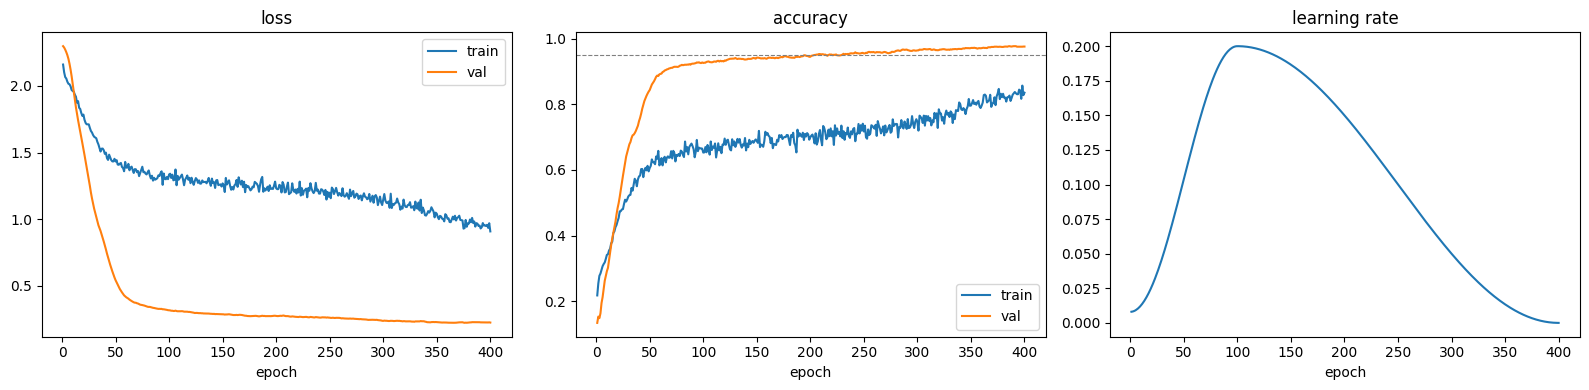

In [14]:
h = pd.DataFrame(state["history"])
if len(h):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val"); ax[0].set_title("loss"); ax[0].legend()
    ax[1].plot(h.epoch, h.train_acc, label="train"); ax[1].plot(h.epoch, h.val_acc, label="val"); ax[1].set_title("accuracy"); ax[1].legend()
    ax[1].axhline(0.95, ls="--", c="grey", lw=0.8)
    ax[2].plot(h.epoch, h.lr); ax[2].set_title("learning rate")
    for a in ax: a.set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "curves.png"), dpi=120); plt.show()

## 12. Honest evaluation of `best.pt` on the internal held-out test split

best.pt: epoch 386, val acc 0.9768, params 4,845,002
internal test accuracy: 0.9732  (n=2500, TTA=on)
airplane      0.972
automobile    0.972
bird          0.948
cat           0.960
deer          0.984
dog           0.960
frog          0.976
horse         0.980
ship          0.988
truck         0.992


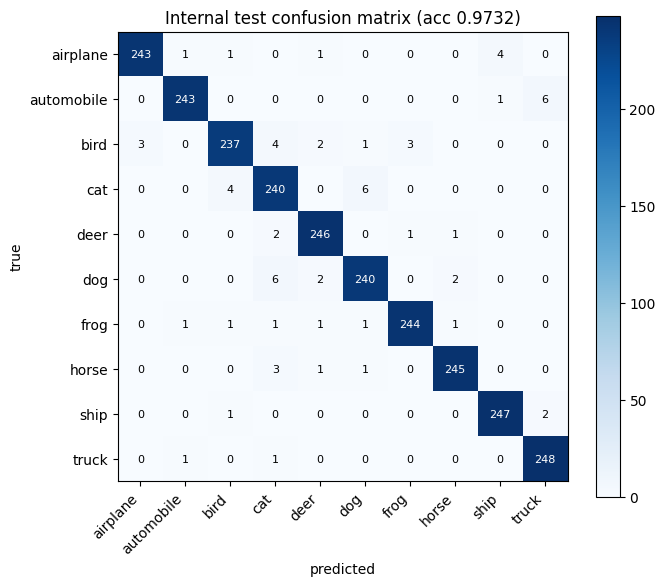

In [15]:
best = torch.load(BEST_CKPT, map_location=device, weights_only=False)
eval_model = build_model(best["cfg"]).to(device).to(memory_format=torch.channels_last)
eval_model.load_state_dict(best["model"])
print(f"best.pt: epoch {best['epoch']}, val acc {best['val_acc']:.4f}, params {count_params(eval_model):,}")

probs = predict_logits(eval_model, Xte_int, tta=CFG["TTA_FLIP"])
pred = probs.argmax(1)
test_acc = (pred == yte_int).float().mean().item()
print(f"internal test accuracy: {test_acc:.4f}  (n={len(yte_int)}, TTA={'on' if CFG['TTA_FLIP'] else 'off'})")
if not CFG["TTA_FLIP"]:
    print(f"(for reference, with flip TTA: {evaluate(eval_model, Xte_int, yte_int, tta=True):.4f})")

cm = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(yte_int.cpu(), pred.cpu()): cm[t, p] += 1
per_class = (cm.diag().float() / cm.sum(1).float()).numpy()
print(pd.Series(per_class, index=CLASS_NAMES).round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm.numpy(), cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right"); ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Internal test confusion matrix (acc {test_acc:.4f})")
plt.colorbar(im); plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "confusion_internal_test.png"), dpi=120); plt.show()
with open(os.path.join(RUN_DIR, "results.json"), "w") as f:
    json.dump({"best_epoch": best["epoch"], "val_acc": best["val_acc"], "internal_test_acc": test_acc,
               "per_class": dict(zip(CLASS_NAMES, per_class.round(4).tolist())), "n_params": N_PARAMS}, f, indent=1)

## 13. Kaggle submission

saved: /content/drive/MyDrive/cifar10_resnet_challenge/runs/resnext29_4x24d_ta_ema_cutmix_sam_v1/submission_20261031_0022_val0.9768_test0.9732.csv 
and: /content/work/submission.csv
predicted class distribution: {'airplane': 165, 'automobile': 218, 'bird': 207, 'cat': 203, 'deer': 200, 'dog': 207, 'frog': 185, 'horse': 203, 'ship': 210, 'truck': 202}


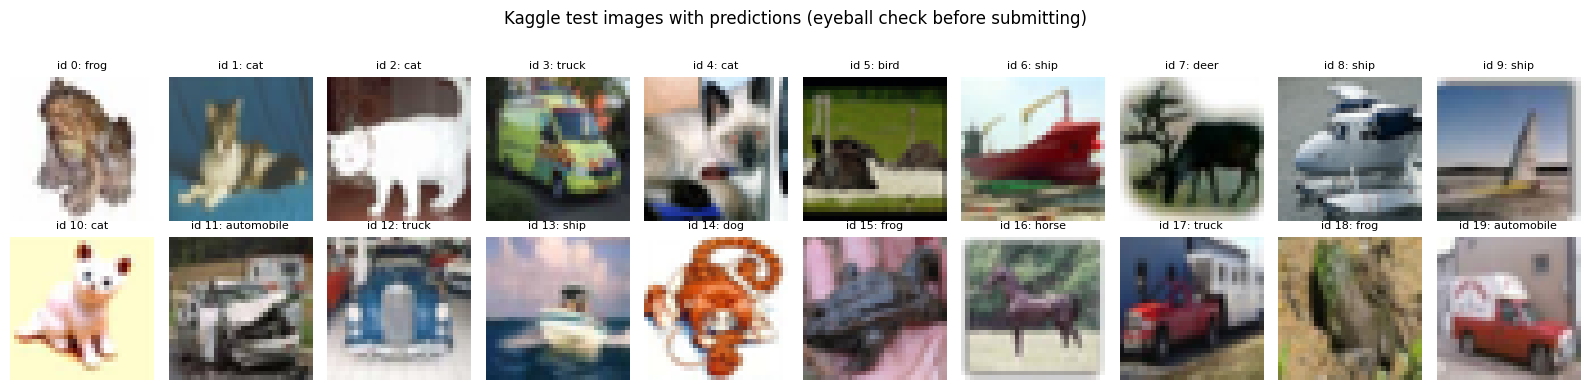

In [16]:
kp = predict_logits(eval_model, Xkaggle, tta=CFG["TTA_FLIP"]).argmax(1).cpu().numpy()
sub = pd.DataFrame({"id": test_ids.astype(int), "label": kp.astype(int)})
assert list(sub.columns) == ["id", "label"] and len(sub) == len(SAMPLE_SUB)
assert (sub["id"].values == SAMPLE_SUB["id"].values).all() and sub["label"].between(0, 9).all()
stamp = time.strftime("%Y%m%d_%H%M")
drive_sub = os.path.join(RUN_DIR, f"submission_{stamp}_val{best['val_acc']:.4f}_test{test_acc:.4f}.csv")
sub.to_csv(drive_sub, index=False)
local_sub = os.path.join(WORK_DIR, "submission.csv"); sub.to_csv(local_sub, index=False)
print("saved:", drive_sub, "\nand:", local_sub)
print("predicted class distribution:", dict(zip(CLASS_NAMES, np.bincount(kp, minlength=10).tolist())))

fig, axs = plt.subplots(2, 10, figsize=(16, 3.8))
for a, i in zip(axs.flat, range(20)):
    a.imshow(X_test[i]); a.set_title(f"id {test_ids[i]}: {CLASS_NAMES[kp[i]]}", fontsize=8); a.axis("off")
plt.suptitle("Kaggle test images with predictions (eyeball check before submitting)", y=1.03); plt.tight_layout(); plt.show()

                              train  internal test  kaggle  kaggle / train  shift (in train std units)
stat                                                                                                  
brightness                   0.4812         0.4840  0.4982          1.0352                      0.1363
contrast (gray std)          0.1951         0.1964  0.2063          1.0576                      0.1902
saturation                   0.1343         0.1311  0.1261          0.9392                     -0.0991
sharpness (laplacian var)    0.0361         0.0366  0.0420          1.1644                      0.2815
high-freq energy ratio       0.0844         0.0848  0.0874          1.0353                      0.0669
noise (median |hp residual|) 0.0236         0.0238  0.0256          1.0842                      0.1536
jpeg blockiness (1.0 = none) 1.0438         1.0366  1.0368          0.9933                     -0.0263
R mean                       0.4916         0.4967  0.5130          1.043

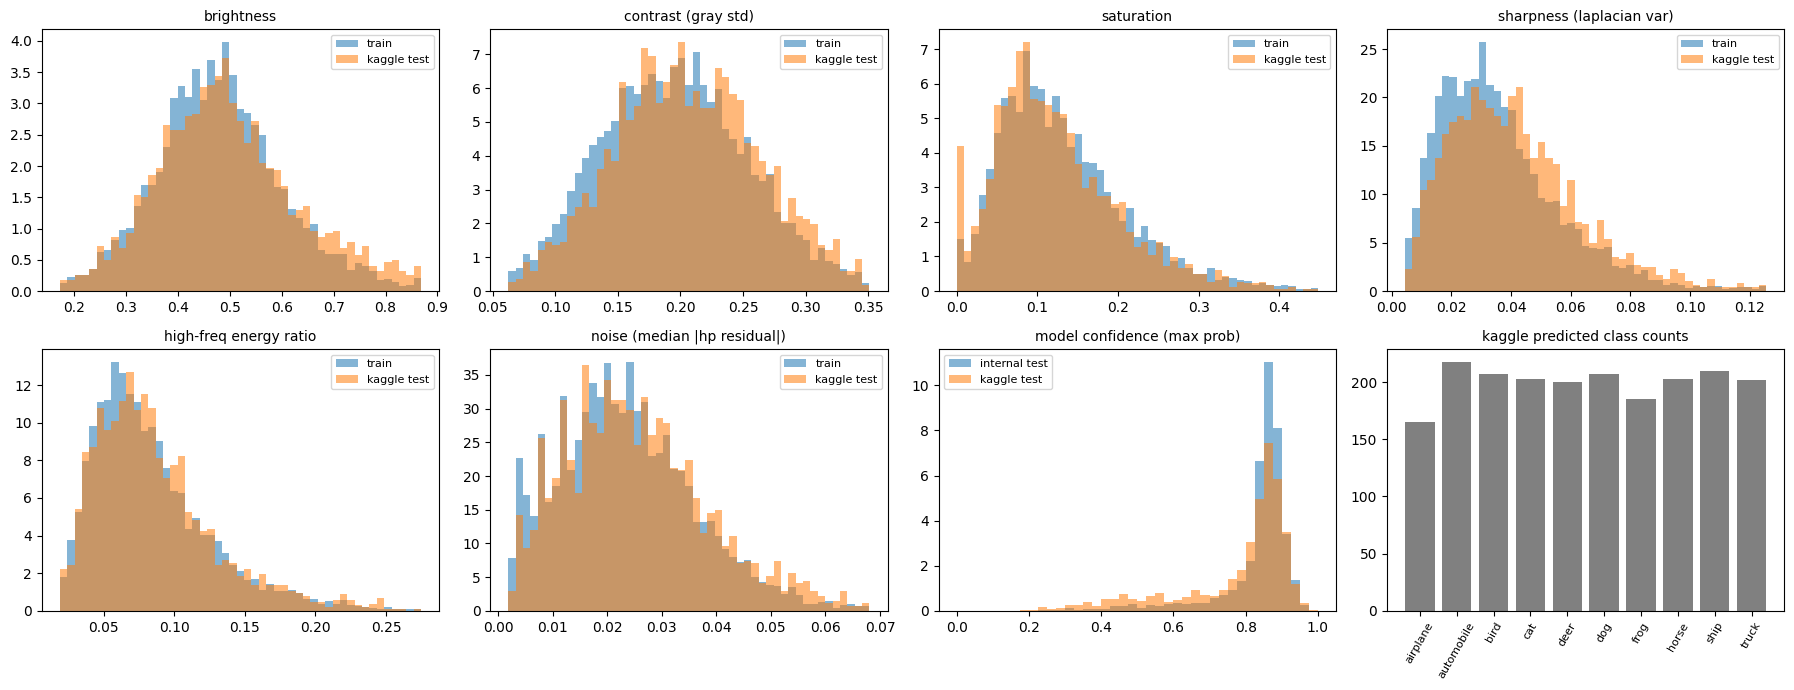

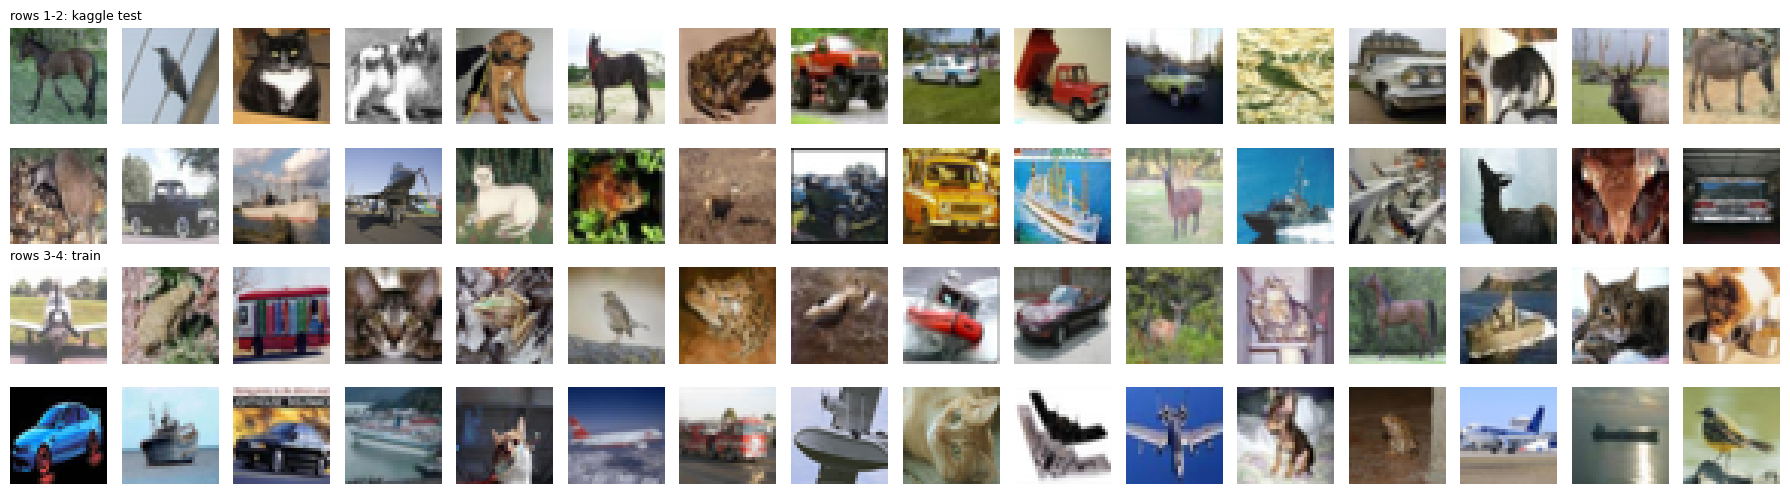

In [17]:
# ---- Diagnostic: how do the Kaggle test images differ from the training images? (no labels used) ----
def img_stats(X):
    """X: N,32,32,3 uint8 -> dict of per-image statistics."""
    x = X.astype(np.float32) / 255.0
    g = x @ np.array([0.299, 0.587, 0.114], dtype=np.float32)                      # grayscale N,32,32
    lap = (g[:, 1:-1, 1:-1] * 4 - g[:, :-2, 1:-1] - g[:, 2:, 1:-1] - g[:, 1:-1, :-2] - g[:, 1:-1, 2:])
    F2 = np.abs(np.fft.fftshift(np.fft.fft2(g - g.mean(axis=(1, 2), keepdims=True)), axes=(1, 2))) ** 2
    yy, xx = np.mgrid[-16:16, -16:16]; hf = np.sqrt(yy ** 2 + xx ** 2) > 8
    dcol = np.abs(np.diff(g, axis=2)); edge_cols = np.arange(7, 31, 8)              # JPEG 8x8 block boundaries
    block = dcol[:, :, edge_cols].mean(axis=(1, 2)) / (np.delete(dcol, edge_cols, axis=2).mean(axis=(1, 2)) + 1e-8)
    resid = g[:, 1:, 1:] - g[:, :-1, 1:] - g[:, 1:, :-1] + g[:, :-1, :-1]
    return {
        "brightness": g.mean(axis=(1, 2)),
        "contrast (gray std)": g.std(axis=(1, 2)),
        "saturation": (x.max(-1) - x.min(-1)).mean(axis=(1, 2)),
        "sharpness (laplacian var)": lap.var(axis=(1, 2)),
        "high-freq energy ratio": F2[:, hf].sum(1) / (F2.reshape(len(x), -1).sum(1) + 1e-8),
        "noise (median |hp residual|)": np.median(np.abs(resid).reshape(len(x), -1), axis=1),
        "jpeg blockiness (1.0 = none)": block,
        "R mean": x[..., 0].mean(axis=(1, 2)), "G mean": x[..., 1].mean(axis=(1, 2)), "B mean": x[..., 2].mean(axis=(1, 2)),
    }

rng = np.random.default_rng(0)
sets = {"train (5k sample)": X_full[rng.choice(tr_idx, min(5000, len(tr_idx)), replace=False)],
        "internal test": X_full[te_idx],
        "kaggle test": X_test}
S = {k: img_stats(v) for k, v in sets.items()}
rows = []
for m in S["kaggle test"]:
    tr, kg = S["train (5k sample)"][m], S["kaggle test"][m]
    rows.append({"stat": m, "train": tr.mean(), "internal test": S["internal test"][m].mean(), "kaggle": kg.mean(),
                 "kaggle / train": kg.mean() / (tr.mean() + 1e-8),
                 "shift (in train std units)": (kg.mean() - tr.mean()) / (tr.std() + 1e-8)})
diag = pd.DataFrame(rows).set_index("stat")
pd.set_option("display.float_format", "{:.4f}".format); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 10)
print(diag)
print("\nRule of thumb: |shift| below 0.1 = same as train, 0.1-0.3 = mild, above 0.3 = clear difference.")

# model confidence: lower confidence on Kaggle = model sees those images as unfamiliar
conf = {}
for name, X in [("internal test", Xte_int), ("kaggle test", Xkaggle)]:
    p = predict_logits(eval_model, X, tta=False)
    conf[name] = p.max(1).values.cpu().numpy()
    ent = -(p * torch.log(p + 1e-12)).sum(1).mean().item()
    print(f"{name:14s} mean max-prob {conf[name].mean():.4f} | share with max-prob < 0.5: {(conf[name] < 0.5).mean():.3f} | mean entropy {ent:.4f}")

# plots: distribution of the key statistics, train vs kaggle
keys = ["brightness", "contrast (gray std)", "saturation", "sharpness (laplacian var)", "high-freq energy ratio", "noise (median |hp residual|)"]
fig, axs = plt.subplots(2, 4, figsize=(18, 7))
for a, k in zip(axs.flat, keys):
    lo, hi = np.percentile(np.concatenate([S["train (5k sample)"][k], S["kaggle test"][k]]), [0.5, 99.5])
    bins = np.linspace(lo, hi, 50)
    a.hist(S["train (5k sample)"][k], bins, density=True, alpha=0.55, label="train")
    a.hist(S["kaggle test"][k], bins, density=True, alpha=0.55, label="kaggle test")
    a.set_title(k, fontsize=10); a.legend(fontsize=8)
a = axs.flat[6]
bins = np.linspace(0, 1, 41)
a.hist(conf["internal test"], bins, density=True, alpha=0.55, label="internal test")
a.hist(conf["kaggle test"], bins, density=True, alpha=0.55, label="kaggle test")
a.set_title("model confidence (max prob)", fontsize=10); a.legend(fontsize=8)
a = axs.flat[7]
a.bar(range(10), np.bincount(predict_logits(eval_model, Xkaggle, tta=True).argmax(1).cpu().numpy(), minlength=10), color="grey")
a.set_xticks(range(10)); a.set_xticklabels(CLASS_NAMES, rotation=60, fontsize=8); a.set_title("kaggle predicted class counts", fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "shift_diagnostic.png"), dpi=110); plt.show()

# 32 random kaggle images next to 32 random train images, same scale, no smoothing
fig, axs = plt.subplots(4, 16, figsize=(18, 5))
ti = rng.choice(len(X_test), 32, replace=False); ri = rng.choice(tr_idx, 32, replace=False)
for k, a in enumerate(axs.flat):
    img = X_full[ri[k - 32]] if k >= 32 else X_test[ti[k]]
    a.imshow(img, interpolation="nearest"); a.axis("off")
axs[0, 0].set_title("rows 1-2: kaggle test", fontsize=9, loc="left"); axs[2, 0].set_title("rows 3-4: train", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

In [18]:
# ---- 5. Ensemble check: disagreement and averaged accuracy of several runs ----
ENSEMBLE_RUNS = ["resnet_w64-128-256_b443_ta_ema_cutmix_sam_v1",
                 "resnext29_4x24d_ta_ema_cutmix_sam_v1"]

va_idx = np.load(split)["val"]
Xva, yva = to_t(X_full[va_idx]), torch.from_numpy(y_full[va_idx]).to(device)

@torch.no_grad()
def run_probs(m, mean, std, X_u8, bs=500):
    out = []
    for i in range(0, len(X_u8), bs):
        x = ((X_u8[i:i + bs].float() / 255 - mean) / std).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device.type, dtype=AMP or torch.float32, enabled=AMP is not None):
            out.append((m(x).float().softmax(1) + m(x.flip(3)).float().softmax(1)) / 2)
    return torch.cat(out)

P = {}
for rn in ENSEMBLE_RUNS:
    c = torch.load(os.path.join(DRIVE_ROOT, "runs", rn, "best.pt"), map_location=device, weights_only=False)
    m = build_model(c["cfg"]).to(device).to(memory_format=torch.channels_last); m.load_state_dict(c["model"]); m.eval()
    mu, sd = c["norm"]["mean"].to(device), c["norm"]["std"].to(device)
    P[rn] = {"val": run_probs(m, mu, sd, Xva), "test": run_probs(m, mu, sd, Xte), "kaggle": run_probs(m, mu, sd, Xk)}
    del m

def cd_errors(pred, y):
    cat, dog = CLASS_NAMES.index("cat"), CLASS_NAMES.index("dog")
    return int(((y == cat) & (pred == dog)).sum()), int(((y == dog) & (pred == cat)).sum())

rows = []
for rn in ENSEMBLE_RUNS:
    pt = P[rn]["test"].argmax(1)
    rows.append({"model": rn, "val": (P[rn]["val"].argmax(1) == yva).float().mean().item(),
                 "internal test": (pt == yte).float().mean().item(), "errors": int((pt != yte).sum()),
                 "cat->dog, dog->cat": cd_errors(pt, yte)})
ens = {s: sum(P[rn][s] for rn in ENSEMBLE_RUNS) / len(ENSEMBLE_RUNS) for s in ("val", "test", "kaggle")}
pe = ens["test"].argmax(1)
rows.append({"model": f"AVERAGE of {len(ENSEMBLE_RUNS)}", "val": (ens["val"].argmax(1) == yva).float().mean().item(),
             "internal test": (pe == yte).float().mean().item(), "errors": int((pe != yte).sum()),
             "cat->dog, dog->cat": cd_errors(pe, yte)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

names = list(P)
print("\nhow often each pair of models disagrees (internal test / kaggle):")
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        dt = (P[names[i]]["test"].argmax(1) != P[names[j]]["test"].argmax(1)).float().mean().item()
        dk = (P[names[i]]["kaggle"].argmax(1) != P[names[j]]["kaggle"].argmax(1)).float().mean().item()
        print(f"  {names[i][:28]:28s} vs {names[j][:28]:28s}: {dt:.1%} / {dk:.1%}")

NameError: name 'split' is not defined